In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
import glob

# --- Configuration ---
base_dir = Path("../data/predictions")
output_dir = Path("../figures/predictions")
rcp_scenarios = ["RCP26", "RCP45", "RCP85"]
PREDICTION_START_INVNR = 550
PLOT_END_YEAR = 2099

# Run diagnostic to check the number of unique plots per vegetation belt
RUN_DIAGNOSTIC = False

# Plotting-Specific Configuration
sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.55,
    "grid.color": "#D7D7D7",
    "grid.alpha": 0.7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# Palettes and Mappings
COLOR_PALETTE = {"RCP26": "#2C7BB6", "RCP45": "#F59E0B", "RCP85": "#D73027"}
MANAGEMENT_MAP = {1.0: 'Managed', 3.0: 'Unmanaged'}
LINESTYLE_MAP = {'Managed': 'solid', 'Unmanaged': (0, (4, 2))}
VEG_BELT_MAP = {
    1: {'long': 'Upper Subalpine', 'short': 'US'},
    2: {'long': 'Subalpine', 'short': 'SA'},
    3: {'long': 'High-Montane', 'short': 'HM'},
    4: {'long': 'Upper Montane (N)', 'short': 'UM'},
    5: {'long': 'Lower Montane (N)', 'short': 'LM'},
    6: {'long': 'Lower/Upper Montane (S)', 'short': 'MO'},
    7: {'long': 'Submontane (N)', 'short': 'SM'},
    8: {'long': 'Colline with Beech (S)', 'short': 'CO'},
    9: {'long': 'Colline', 'short': 'CO'},
    10: {'long': 'Hyperinsubric (S)', 'short': 'HY'}
}
VEG_BELT_ORDER = ['CO', 'SM', 'LM', 'MO', 'UM', 'HM', 'SA', 'US', 'HY']

# Font Sizes
TITLE_FONTSIZE = 13
AXIS_LABEL_FONTSIZE = 11
TICK_LABEL_FONTSIZE = 9
LEGEND_FONTSIZE = 9

print("Configuration loaded successfully.")
print(f"Data will be read from and plots saved to: {base_dir} and {output_dir} respectively.")


Configuration loaded successfully.
Data will be read from and plots saved to: ../data/predictions and ../figures/predictions respectively.


In [2]:
# --- Load and combine all simulation data ---

all_scenarios_data = []
print("\nStarting to load and combine prediction data...")
for rcp in rcp_scenarios:
    scenario_dir = base_dir / f"Predictions_{rcp}"
    prediction_files = glob.glob(str(scenario_dir / f"NFI_{rcp}_prediction_seed_*.csv"))
    
    scenario_dfs = [pd.read_csv(file) for file in prediction_files]
    for i, df in enumerate(scenario_dfs):
        df['seed'] = int(Path(prediction_files[i]).stem.split('_seed_')[-1])
        
    combined_df = pd.concat(scenario_dfs, ignore_index=True)
    combined_df['rcp'] = rcp
    all_scenarios_data.append(combined_df)


master_df = pd.concat(all_scenarios_data, ignore_index=True)
print("\nMaster DataFrame created successfully.")
print(f"Shape: {master_df.shape}")



Starting to load and combine prediction data...

Master DataFrame created successfully.
Shape: (468000, 36)


In [3]:
# --- Feature coverage / hull fraction helpers ---

# Same climate feature set used in feature_coverage_analysis.ipynb.
CLIMATE_FEATURES = [
    'mean_dry_days_count', 'mean_frost_days_count', 'mean_gdd_sum',
    'mean_pr_sum', 'mean_pr_variance', 'mean_tas_mean', 'mean_tas_variance',
    'mean_tasmax_mean', 'mean_tasmax_variance', 'mean_tasmin_mean',
    'mean_tasmin_variance'
]

HULL_FRACTION_COL = 'frac_outside_hull'
HULL_AXIS_LABEL = 'Outside hull (%)'
HULL_THRESHOLD_PCT = 10
HULL_CMAP = LinearSegmentedColormap.from_list(
    'hull_risk', ['#F7F7F7', '#FEE8A8', '#F59E0B', '#D73027', '#7F0000']
)


def _unique_preserve_order(cols):
    return list(dict.fromkeys(cols))


def _build_training_hull_limits(df, training_rcp='RCP45'):
    """Training min/max climate hull, matching feature_coverage_analysis.ipynb."""
    train = df[
        (df['rcp'] == training_rcp)
        & (df['INVNR'] <= PREDICTION_START_INVNR)
    ][['CLNR', 'INVNR'] + CLIMATE_FEATURES].dropna(subset=CLIMATE_FEATURES)
    train = train.drop_duplicates(['CLNR', 'INVNR'])

    if train.empty:
        raise ValueError('No complete training rows available to build the climate hull.')

    return {
        feat: {'min': train[feat].min(), 'max': train[feat].max()}
        for feat in CLIMATE_FEATURES
    }


def calculate_hull_fraction(
    df,
    group_cols,
    year_map=None,
    prediction_start_invnr=PREDICTION_START_INVNR,
):
    """
    Fraction of unique plots outside the training climate hull.

    Prediction files contain one copy per random seed, while climate inputs are seed-invariant.
    We therefore de-duplicate by plot before calculating the fraction.
    """
    group_cols = list(group_cols)
    required_cols = _unique_preserve_order(group_cols + ['rcp', 'INVNR', 'CLNR'] + CLIMATE_FEATURES)
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        raise KeyError(f'Missing columns for hull-fraction calculation: {missing_cols}')

    hull_rows = (
        df.loc[df['INVNR'] >= prediction_start_invnr, required_cols]
          .dropna(subset=CLIMATE_FEATURES)
          .copy()
    )

    if hull_rows.empty:
        result = pd.DataFrame(columns=group_cols + ['n_hull_plots', HULL_FRACTION_COL])
    else:
        dedupe_cols = _unique_preserve_order(
            ['rcp', 'INVNR', 'CLNR'] + [col for col in group_cols if col not in ['rcp', 'INVNR']]
        )
        hull_rows = hull_rows.drop_duplicates(dedupe_cols)

        outside_any = pd.Series(False, index=hull_rows.index)
        for feat, limits in training_hull_limits.items():
            outside_any = outside_any | hull_rows[feat].lt(limits['min']) | hull_rows[feat].gt(limits['max'])
        hull_rows['outside_training_hull'] = outside_any

        result = (
            hull_rows.groupby(group_cols, as_index=False)
                     .agg(
                         n_hull_plots=('outside_training_hull', 'size'),
                         **{HULL_FRACTION_COL: ('outside_training_hull', 'mean')},
                     )
        )

    if year_map is not None and 'INVNR' in group_cols:
        year_cols = ['INVNR', 'median_year_per_INVNR']
        if 'interval_end_year' in year_map.columns:
            year_cols.append('interval_end_year')
        result = (
            result.merge(year_map[year_cols].drop_duplicates(),
                         on='INVNR', how='left')
                  .rename(columns={'median_year_per_INVNR': 'mean_year'})
        )

    return result


def _hull_color_vmax(hull_data, minimum=10):
    if hull_data is None or hull_data.empty or HULL_FRACTION_COL not in hull_data.columns:
        return minimum

    max_value = hull_data[HULL_FRACTION_COL].max() * 100
    if pd.isna(max_value):
        return minimum

    return max(minimum, int(np.ceil(max_value / 5) * 5))


def _year_edges(years):
    years = np.asarray(sorted(pd.Series(years).dropna().unique()), dtype=float)
    if len(years) == 0:
        return years
    if len(years) == 1:
        return np.array([years[0] - 0.5, years[0] + 0.5])

    mids = (years[:-1] + years[1:]) / 2
    first = years[0] - (mids[0] - years[0])
    last = years[-1] + (years[-1] - mids[-1])
    return np.r_[first, mids, last]


def _plot_hull_risk_strip(
    ax,
    hull_data,
    x_col='mean_year',
    rcp_order=rcp_scenarios,
    cmap=HULL_CMAP,
    norm=None,
    show_ylabel=True,
    show_xticklabels=True,
    annotate=False,
    annotation_threshold=1.0,
):
    """Compact, x-aligned heatmap strip for the outside-hull fraction."""
    if hull_data is None or hull_data.empty or HULL_FRACTION_COL not in hull_data.columns:
        ax.set_visible(False)
        return None

    years = sorted(hull_data[x_col].dropna().unique())
    if not years:
        ax.set_visible(False)
        return None

    pivot = (
        hull_data.pivot_table(index='rcp', columns=x_col, values=HULL_FRACTION_COL, aggfunc='mean')
                 .reindex(index=rcp_order, columns=years)
                 .mul(100)
    )
    values = np.ma.masked_invalid(pivot.to_numpy(dtype=float))
    x_edges = _year_edges(years)
    y_edges = np.arange(len(rcp_order) + 1)
    norm = norm or mpl.colors.Normalize(vmin=0, vmax=_hull_color_vmax(hull_data))

    mesh = ax.pcolormesh(
        x_edges, y_edges, values,
        cmap=cmap, norm=norm, shading='flat',
        edgecolors='white', linewidth=0.8, rasterized=True,
    )
    ax.set_ylim(len(rcp_order), 0)
    ax.set_yticks(np.arange(len(rcp_order)) + 0.5)
    ax.set_yticklabels(rcp_order if show_ylabel else [])
    ax.tick_params(axis='y', labelsize=8, length=0)
    ax.tick_params(axis='x', labelsize=8, length=2, color='#666666')
    ax.set_xticks(years)

    if not show_xticklabels:
        ax.tick_params(axis='x', labelbottom=False)
    else:
        ax.set_xticklabels([str(int(y)) for y in years], rotation=0)

    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

    if annotate:
        for row_idx, rcp in enumerate(rcp_order):
            for year in years:
                value = pivot.loc[rcp, year]
                if pd.isna(value) or value < annotation_threshold:
                    continue
                text_color = 'white' if value > norm.vmax * 0.58 else '#2B2B2B'
                ax.text(
                    year, row_idx + 0.5, f'{value:.0f}',
                    ha='center', va='center', fontsize=7.2, color=text_color,
                )

    return mesh


def _format_main_axis(ax, prediction_start_year, y_label, ylim=None):
    ax.axvline(prediction_start_year, color='#4D4D4D', linestyle=':', lw=1.4, alpha=0.85)
    ax.set_ylabel(y_label, fontsize=AXIS_LABEL_FONTSIZE)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.grid(True, axis='y')
    ax.grid(False, axis='x')
    ax.tick_params(axis='both', which='major', labelsize=TICK_LABEL_FONTSIZE, color='#555555')
    sns.despine(ax=ax)


def _add_prediction_start_label(ax, prediction_start_year):
    # Kept as a hook; the vertical line is explained in the figure caption.
    return None


def _save_and_show(fig, output_filename):
    pdf_path = output_filename.with_suffix('.pdf')
    fig.savefig(pdf_path, bbox_inches='tight')
    print(f"Saved PDF to: {pdf_path}")
    plt.show()


training_hull_limits = _build_training_hull_limits(master_df)
print(f'Training climate hull built from complete climate rows up to INVNR {PREDICTION_START_INVNR}.')


Training climate hull built from complete climate rows up to INVNR 550.


In [4]:
# --- Prepare data for management-type plots ---

# Create a mapping from inventory number (INVNR) to the median year for use as the x-axis.
year_map = (
    master_df.groupby('INVNR', as_index=False)['INVYR']
    .median()
    .rename(columns={'INVYR': 'median_year_per_INVNR'})
)
year_map['median_year_per_INVNR'] = year_map['median_year_per_INVNR'].round().astype(int)
year_map = year_map.sort_values('median_year_per_INVNR').reset_index(drop=True)
year_map['interval_end_year'] = year_map['median_year_per_INVNR'].shift(-1)
year_map['interval_end_year'] = year_map['interval_end_year'].fillna(PLOT_END_YEAR).round().astype(int)

hull_fraction_df = calculate_hull_fraction(master_df, ['rcp', 'INVNR'], year_map)

# Filter for managed and unmanaged plots
df_mgmt = master_df[master_df['BEWIRTINT1'].isin(MANAGEMENT_MAP.keys())].copy()
df_mgmt['management_type'] = df_mgmt['BEWIRTINT1'].map(MANAGEMENT_MAP)

# Aggregate by INVNR, SEED, and MANAGEMENT_TYPE
mean_per_invnr_df_mgmt = df_mgmt.groupby(['rcp', 'INVNR', 'seed', 'management_type']).agg(
    mean_BASFPH=('BASFPH', 'mean'),
    mean_HWSW_prop=('HWSW_prop', 'mean')
).reset_index()

# Calculate final statistics across all seeds
plot_stats_df_mgmt = mean_per_invnr_df_mgmt.groupby(['rcp', 'INVNR', 'management_type']).agg(
    final_mean_BASFPH=('mean_BASFPH', 'mean'),
    min_BASFPH=('mean_BASFPH', 'min'),
    max_BASFPH=('mean_BASFPH', 'max'),          
    final_mean_HWSW_prop=('mean_HWSW_prop', 'mean'),
    min_HWSW_prop=('mean_HWSW_prop', 'min'),
    max_HWSW_prop=('mean_HWSW_prop', 'max')       
).reset_index()

# Merge the aggregated statistics
plot_data_management = (
    plot_stats_df_mgmt.merge(year_map, on='INVNR', how='left')
    .rename(columns={'median_year_per_INVNR':'mean_year'})  
)

hull_fraction_management = calculate_hull_fraction(df_mgmt, ['rcp', 'INVNR'], year_map)

# Get the prediction start year for the vertical line
prediction_start_year = plot_data_management[plot_data_management['INVNR'] == PREDICTION_START_INVNR]['mean_year'].iloc[0]

print("Data prepared for management-specific plots.")
print('Outside-hull fractions by RCP and inventory (%):')
print(
    (hull_fraction_df
     .pivot(index='mean_year', columns='rcp', values=HULL_FRACTION_COL)
     .mul(100)
     .round(1)
     .to_string())
)


Data prepared for management-specific plots.
Outside-hull fractions by RCP and inventory (%):
rcp        RCP26  RCP45  RCP85
mean_year                     
2021         0.8    0.0    6.7
2031         1.7    2.5   12.5
2041         5.8    3.3   12.5
2050         2.5    5.0   18.3
2060         3.3    6.7   30.8
2069         5.0   10.0   41.7
2079         4.2    7.5   54.2
2089         5.8   10.0   54.2
2099         5.0   16.7   74.2


Saved PDF to: ../figures/predictions/basal_area_by_management.pdf


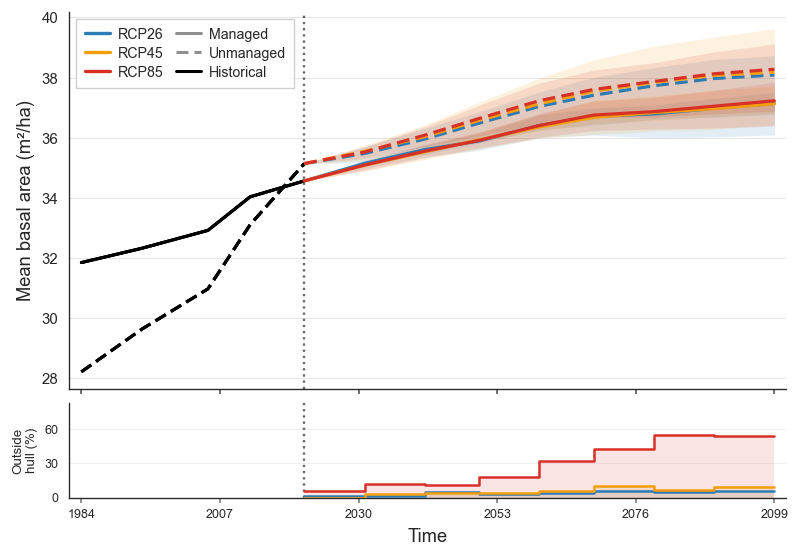

Saved PDF to: ../figures/predictions/hw_proportion_by_management.pdf


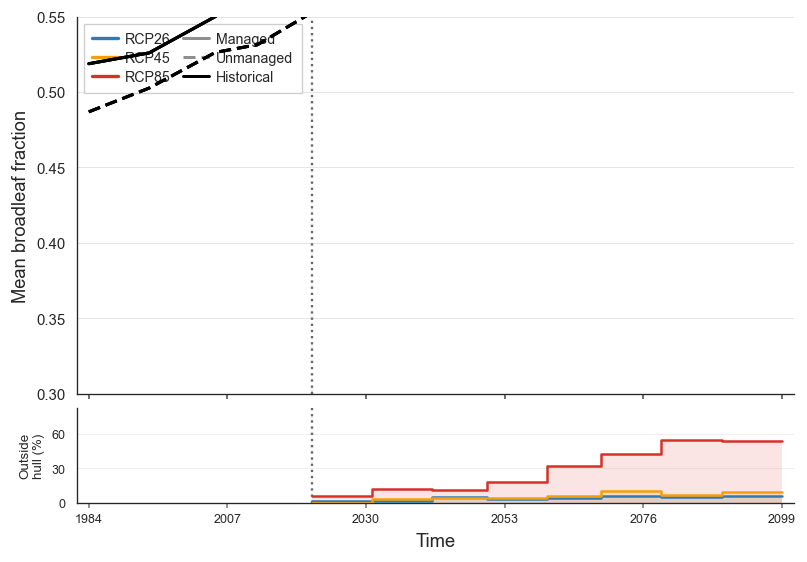

In [5]:
# --- Shared helper: outside-hull line chart panel ---

def _full_period_xticks(years, end_year=PLOT_END_YEAR, n_ticks=6):
    """Evenly spaced x ticks from the first plotted year through the projection end year."""
    year_values = sorted({int(round(y)) for y in pd.Series(years).dropna()})
    if not year_values:
        return []
    start_year = year_values[0]
    if start_year >= end_year:
        return [start_year]
    return np.linspace(start_year, end_year, n_ticks).tolist()


def _hull_interval_values(sub, x_col, end_col='interval_end_year', end_year=PLOT_END_YEAR):
    starts = sub[x_col].astype(float).to_numpy()
    vals = (sub[HULL_FRACTION_COL] * 100).astype(float).to_numpy()
    if len(starts) == 0:
        return starts, starts, vals
    fallback_ends = np.r_[starts[1:], float(end_year)]
    if end_col in sub.columns:
        ends = sub[end_col].astype(float).to_numpy()
        ends = np.where(np.isfinite(ends), ends, fallback_ends)
    else:
        ends = fallback_ends
    valid = np.isfinite(starts) & np.isfinite(ends) & np.isfinite(vals) & (ends > starts)
    return starts[valid], ends[valid], vals[valid]


def _plot_hull_interval_step(ax, sub, x_col, color, linewidth=1.5, alpha=0.12, zorder=5):
    starts, ends, vals = _hull_interval_values(sub, x_col)
    if len(starts) == 0:
        return

    run_start = 0
    for i in range(1, len(starts) + 1):
        at_break = i == len(starts) or not np.isclose(starts[i], ends[i - 1])
        if not at_break:
            continue
        run_starts = starts[run_start:i]
        run_ends = ends[run_start:i]
        run_vals = vals[run_start:i]
        x_step = np.r_[run_starts, run_ends[-1]]
        y_step = np.r_[run_vals, run_vals[-1]]
        ax.step(x_step, y_step, where='post', color=color, linewidth=linewidth, zorder=zorder)
        ax.fill_between(x_step, 0, y_step, step='post', color=color, alpha=alpha, linewidth=0)
        run_start = i


def _draw_hull_line_panel(ax_hull, hull_data, x_col, color_palette, rcp_scenarios, x_ticks):
    for rcp in rcp_scenarios:
        sub = hull_data[hull_data['rcp'] == rcp].sort_values(x_col)
        if sub.empty:
            continue
        _plot_hull_interval_step(
            ax_hull, sub, x_col, color_palette[rcp], linewidth=1.5, alpha=0.12, zorder=5
        )

    vmax = hull_data[HULL_FRACTION_COL].max() * 100
    ax_hull.set_ylim(0, max(35, vmax * 1.1))
    ax_hull.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=3, integer=True))
    ax_hull.set_ylabel('Outside\nhull (%)', fontsize=8, labelpad=4)
    ax_hull.grid(True, axis='y', linewidth=0.4, alpha=0.6)
    ax_hull.grid(False, axis='x')
    # Label the shared x-axis over the full plot period, not just years with hull data.
    tick_years_set = {int(round(y)) for y in x_ticks}
    ax_hull.xaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(
            lambda x, p: str(int(round(x))) if int(round(x)) in tick_years_set else ''
        )
    )
    ax_hull.tick_params(axis='both', which='major', labelsize=7.5, color='#7F7F7F',
                        length=3, bottom=True)
    sns.despine(ax=ax_hull)


# --- Plotting function: by management ---

def create_plot_by_management(
    data, x_col, y_mean_col, y_min_col, y_max_col,
    y_label, title, output_filename,
    color_palette, linestyle_map, prediction_start_year, ylim=None,
    hull_fraction_data=None,
):
    has_hull = hull_fraction_data is not None and not hull_fraction_data.empty

    fig = plt.figure(figsize=(7.2, 5.0 if has_hull else 3.8))
    if has_hull:
        gs = fig.add_gridspec(2, 1, height_ratios=[4, 1], hspace=0.06,
                              left=0.11, right=0.94, bottom=0.12, top=0.93)
    else:
        gs = fig.add_gridspec(1, 1, left=0.11, right=0.94, bottom=0.12, top=0.95)
    ax = fig.add_subplot(gs[0])
    ax_hull = fig.add_subplot(gs[1], sharex=ax) if has_hull else None

    for rcp in rcp_scenarios:
        for mgmt_type, linestyle in linestyle_map.items():
            sub = data[
                (data['rcp'] == rcp) & (data['management_type'] == mgmt_type)
            ].sort_values(x_col)
            if sub.empty:
                continue
            color = color_palette[rcp]
            hist = sub[sub[x_col] <= prediction_start_year]
            fut  = sub[sub[x_col] >= prediction_start_year]

            if not hist.empty:
                ax.plot(hist[x_col], hist[y_mean_col],
                        color='#000000', linewidth=1.8, linestyle=linestyle, zorder=8)
            if not fut.empty:
                ax.plot(fut[x_col], fut[y_mean_col],
                        color=color, linewidth=1.9, linestyle=linestyle, zorder=9)
                ax.fill_between(fut[x_col], fut[y_min_col], fut[y_max_col],
                                color=color, alpha=0.13, zorder=3, linewidth=0)

    all_data_years = sorted(data[x_col].dropna().unique())
    x_ticks = _full_period_xticks(all_data_years)

    ax.axvline(prediction_start_year, color='#4D4D4D', linestyle=':', lw=1.4, alpha=0.85)
    ax.set_ylabel(y_label, fontsize=AXIS_LABEL_FONTSIZE)
    if ylim is not None:
        ax.set_ylim(ylim)
    if x_ticks:
        ax.set_xlim(x_ticks[0] - 2, x_ticks[-1] + 2)
    ax.grid(True, axis='y', linewidth=0.55, alpha=0.7)
    ax.grid(False, axis='x')
    sns.despine(ax=ax)
    if title:
        ax.set_title(title, fontsize=TITLE_FONTSIZE, pad=8, weight='bold')

    # 2-col x 3-row legend
    leg_handles = [
        Line2D([], [], color=color_palette[rcp_scenarios[0]], lw=2.0),
        Line2D([], [], color=color_palette[rcp_scenarios[1]], lw=2.0),
        Line2D([], [], color=color_palette[rcp_scenarios[2]], lw=2.0),
        Line2D([], [], color="#8F8F8F", lw=1.8, linestyle=linestyle_map['Managed']),
        Line2D([], [], color='#8F8F8F', lw=1.8, linestyle=linestyle_map['Unmanaged']),
        Line2D([], [], color='#000000', lw=1.8),
    ]
    leg_labels = [
        rcp_scenarios[0], rcp_scenarios[1], rcp_scenarios[2],
        'Managed', 'Unmanaged', 'Historical',
    ]
    ax.legend(
        leg_handles, leg_labels,
        loc='upper left', ncol=2,
        frameon=True, framealpha=0.95, edgecolor='#CCCCCC', fancybox=False,
        fontsize=8.5, handlelength=1.8, handletextpad=0.5,
        borderpad=0.6, labelspacing=0.35, columnspacing=0.9,
    )

    # Set ticks on ax BEFORE calling hull panel so the shared locator is not clobbered.
    ax.set_xticks(x_ticks)
    ax.tick_params(axis='both', which='major', labelsize=TICK_LABEL_FONTSIZE,
                   color='#555555', length=3, bottom=True)

    if has_hull:
        # Hide labels on main axis — hull strip carries them via FuncFormatter.
        ax.tick_params(axis='x', which='major', labelbottom=False)
        _draw_hull_line_panel(ax_hull, hull_fraction_data, x_col, color_palette, rcp_scenarios, x_ticks)
        ax_hull.axvline(prediction_start_year, color='#4D4D4D', linestyle=':', lw=1.4, alpha=0.85)
        ax_hull.set_xlabel('Time', fontsize=AXIS_LABEL_FONTSIZE)
    else:
        ax.set_xticklabels([str(int(y)) for y in x_ticks])
        ax.set_xlabel('Time', fontsize=AXIS_LABEL_FONTSIZE)

    _save_and_show(fig, output_filename)


# --- Generate and save the overall management plots ---

create_plot_by_management(
    data=plot_data_management, x_col='mean_year', y_mean_col='final_mean_BASFPH',
    y_min_col='min_BASFPH', y_max_col='max_BASFPH',
    y_label='Mean basal area (m²/ha)',
    title='',
    output_filename=output_dir / 'basal_area_by_management',
    color_palette=COLOR_PALETTE, linestyle_map=LINESTYLE_MAP,
    prediction_start_year=prediction_start_year,
    hull_fraction_data=hull_fraction_management,
)
create_plot_by_management(
    data=plot_data_management, x_col='mean_year', y_mean_col='final_mean_HWSW_prop',
    y_min_col='min_HWSW_prop', y_max_col='max_HWSW_prop',
    y_label='Mean broadleaf fraction',
    title='',
    output_filename=output_dir / 'hw_proportion_by_management',
    color_palette=COLOR_PALETTE, linestyle_map=LINESTYLE_MAP,
    prediction_start_year=prediction_start_year, ylim=(0.3, 0.55),
    hull_fraction_data=hull_fraction_management,
)

Saved PDF to: ../figures/predictions/basal_area_by_scenario.pdf


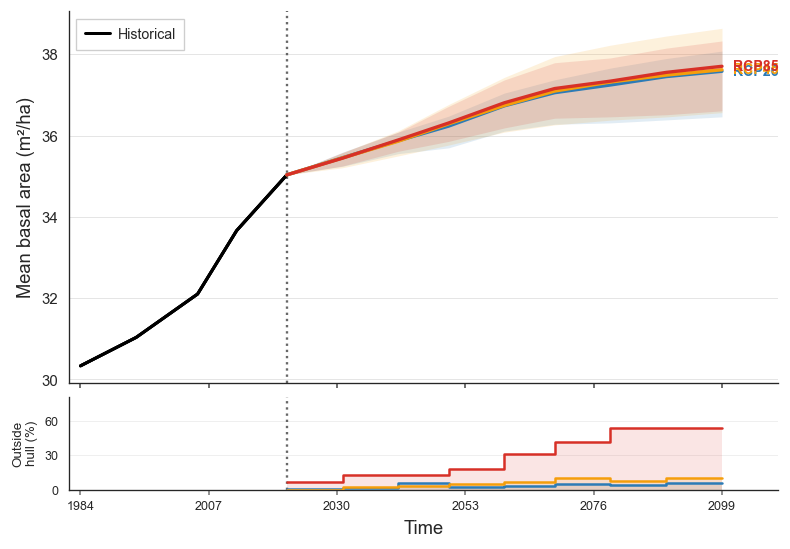

Saved PDF to: ../figures/predictions/hw_proportion_by_scenario.pdf


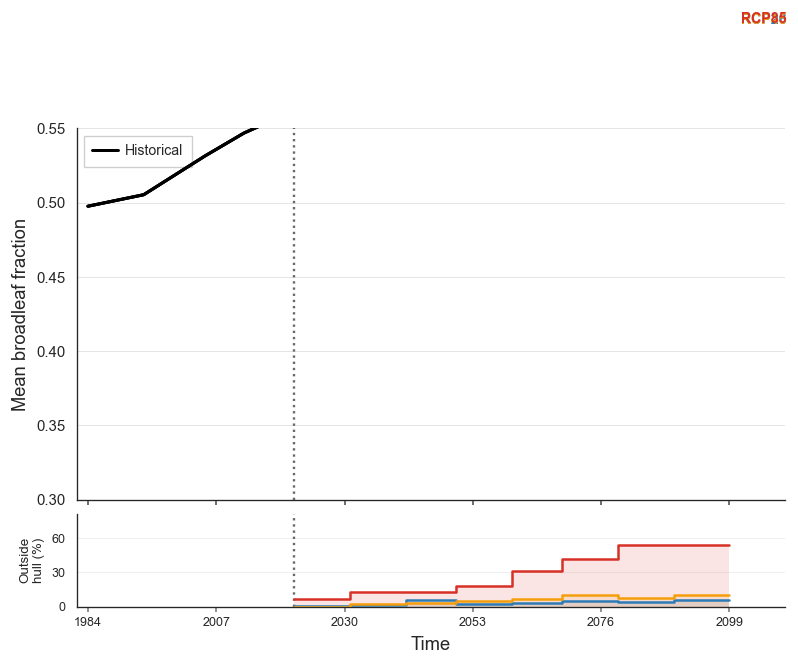

In [6]:
# --- Plotting function: by scenario only ---

def create_plot_by_scenario(
    data, x_col, y_mean_col, y_min_col, y_max_col,
    y_label, title, output_filename,
    color_palette, prediction_start_year, ylim=None,
    hull_fraction_data=None,
):
    """
    Two-panel figure: full time series with historical (gray) + forecast (RCP colors).
    End-of-line RCP labels. Bottom: outside-hull % line chart with full-period x-axis labels.
    """
    has_hull = hull_fraction_data is not None and not hull_fraction_data.empty

    all_years = sorted(data[x_col].dropna().unique())
    x_ticks = _full_period_xticks(all_years)

    fig = plt.figure(figsize=(7.2, 4.8 if has_hull else 3.8))
    if has_hull:
        gs = fig.add_gridspec(2, 1, height_ratios=[4, 1], hspace=0.06,
                              left=0.11, right=0.93, bottom=0.12, top=0.95)
    else:
        gs = fig.add_gridspec(1, 1, left=0.11, right=0.93, bottom=0.12, top=0.95)
    ax = fig.add_subplot(gs[0])
    ax_hull = fig.add_subplot(gs[1], sharex=ax) if has_hull else None

    for rcp in rcp_scenarios:
        sub = data[data['rcp'] == rcp].sort_values(x_col)
        if sub.empty:
            continue
        color = color_palette[rcp]
        hist = sub[sub[x_col] <= prediction_start_year]
        fut  = sub[sub[x_col] >= prediction_start_year]

        if not hist.empty:
            ax.plot(hist[x_col], hist[y_mean_col],
                    color='#000000', linewidth=1.8, zorder=8)
        if not fut.empty:
            ax.plot(fut[x_col], fut[y_mean_col],
                    color=color, linewidth=2.0, zorder=9)
            ax.fill_between(fut[x_col], fut[y_min_col], fut[y_max_col],
                            color=color, alpha=0.14, zorder=3, linewidth=0)
            end = fut.iloc[-1]
            ax.text(end[x_col] + 2, end[y_mean_col], rcp,
                    color=color, fontsize=8.5, fontweight='bold', va='center')

    ax.axvline(prediction_start_year, color='#4D4D4D', linestyle=':', lw=1.4, alpha=0.85)
    ax.set_ylabel(y_label, fontsize=AXIS_LABEL_FONTSIZE)
    if ylim is not None:
        ax.set_ylim(ylim)
    if x_ticks:
        ax.set_xlim(x_ticks[0] - 2, x_ticks[-1] + 10)
    ax.grid(True, axis='y', linewidth=0.55, alpha=0.7)
    ax.grid(False, axis='x')
    sns.despine(ax=ax)
    if title:
        ax.set_title(title, fontsize=TITLE_FONTSIZE, pad=8, weight='bold')

    ax.legend(
        [Line2D([], [], color='#000000', lw=1.8)], ['Historical'],
        loc='upper left',
        frameon=True, framealpha=0.95, edgecolor='#CCCCCC', fancybox=False,
        fontsize=8.5, handlelength=1.8, handletextpad=0.5,
        borderpad=0.6,
    )

    # Set ticks on ax BEFORE calling hull panel so the shared locator is not clobbered.
    ax.set_xticks(x_ticks)
    ax.tick_params(axis='both', which='major', labelsize=TICK_LABEL_FONTSIZE,
                   color='#555555', length=3, bottom=True)

    if has_hull:
        # Hide labels on main axis — hull strip carries them via FuncFormatter.
        ax.tick_params(axis='x', which='major', labelbottom=False)
        _draw_hull_line_panel(ax_hull, hull_fraction_data, x_col, color_palette, rcp_scenarios, x_ticks)
        ax_hull.axvline(prediction_start_year, color='#4D4D4D', linestyle=':', lw=1.4, alpha=0.85)
        ax_hull.set_xlabel('Time', fontsize=AXIS_LABEL_FONTSIZE)
    else:
        ax.set_xticklabels([str(int(y)) for y in x_ticks])
        ax.set_xlabel('Time', fontsize=AXIS_LABEL_FONTSIZE)

    _save_and_show(fig, output_filename)


# --- Build scenario-level data ---

per_seed_means = (
    master_df
    .groupby(['rcp', 'INVNR', 'seed'], as_index=False)
    .agg(
        mean_BASFPH=('BASFPH', 'mean'),
        mean_HWSW_prop=('HWSW_prop', 'mean')
    )
)

plot_data_no_mgmt = (
    per_seed_means
    .groupby(['rcp', 'INVNR'], as_index=False)
    .agg(
        final_mean_BASFPH=('mean_BASFPH', 'mean'),
        min_BASFPH=('mean_BASFPH', 'min'),
        max_BASFPH=('mean_BASFPH', 'max'),
        final_mean_HWSW_prop=('mean_HWSW_prop', 'mean'),
        min_HWSW_prop=('mean_HWSW_prop', 'min'),
        max_HWSW_prop=('mean_HWSW_prop', 'max'),
    )
    .merge(year_map, on='INVNR', how='left')
    .rename(columns={'median_year_per_INVNR': 'mean_year'})
    .sort_values(['rcp', 'mean_year'])
)

prediction_start_year = int(year_map.loc[
    year_map['INVNR'] == PREDICTION_START_INVNR, 'median_year_per_INVNR'
].iloc[0])

# --- Plots ---

create_plot_by_scenario(
    data=plot_data_no_mgmt, x_col='mean_year', y_mean_col='final_mean_BASFPH',
    y_min_col='min_BASFPH', y_max_col='max_BASFPH',
    y_label='Mean basal area (m²/ha)',
    title='',
    output_filename=output_dir / 'basal_area_by_scenario',
    color_palette=COLOR_PALETTE,
    prediction_start_year=prediction_start_year,
    hull_fraction_data=hull_fraction_df,
)

create_plot_by_scenario(
    data=plot_data_no_mgmt, x_col='mean_year', y_mean_col='final_mean_HWSW_prop',
    y_min_col='min_HWSW_prop', y_max_col='max_HWSW_prop',
    y_label='Mean broadleaf fraction',
    title='',
    output_filename=output_dir / 'hw_proportion_by_scenario',
    color_palette=COLOR_PALETTE,
    prediction_start_year=prediction_start_year,
    ylim=(0.3, 0.55),
    hull_fraction_data=hull_fraction_df,
)

Saved PDF to: ../figures/predictions/basal_area_change_by_veg_belt_all_plots.pdf


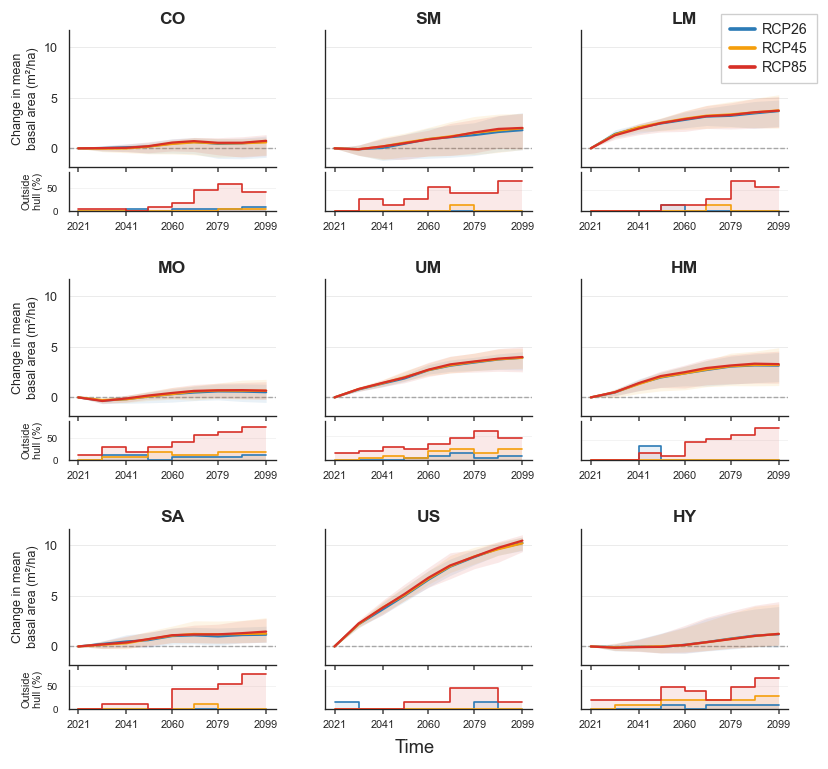

Saved PDF to: ../figures/predictions/basal_area_change_by_veg_belt_managed_only.pdf


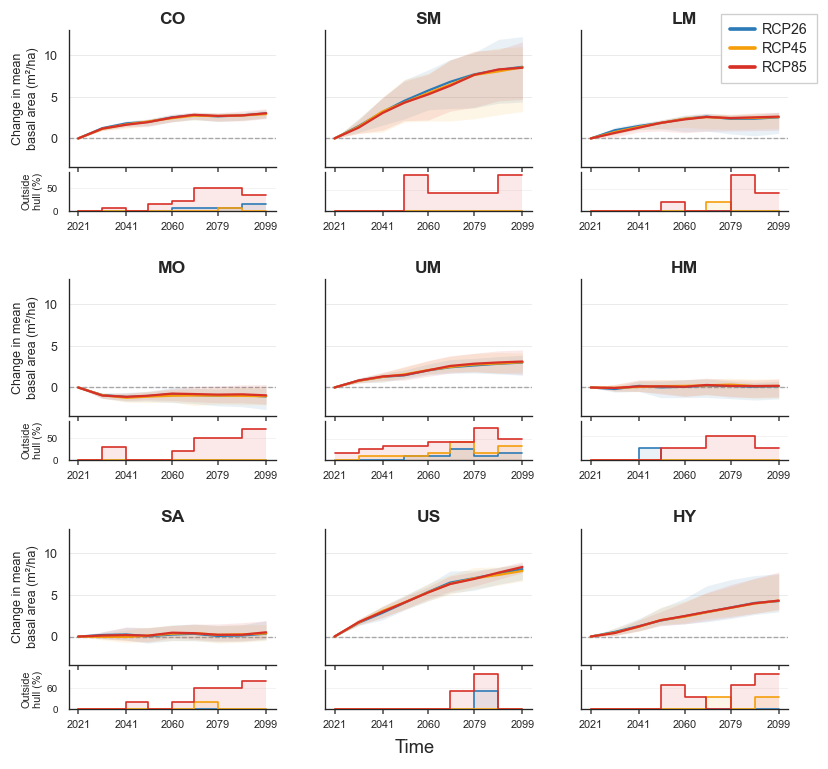

Saved PDF to: ../figures/predictions/basal_area_change_by_veg_belt_unmanaged_only.pdf


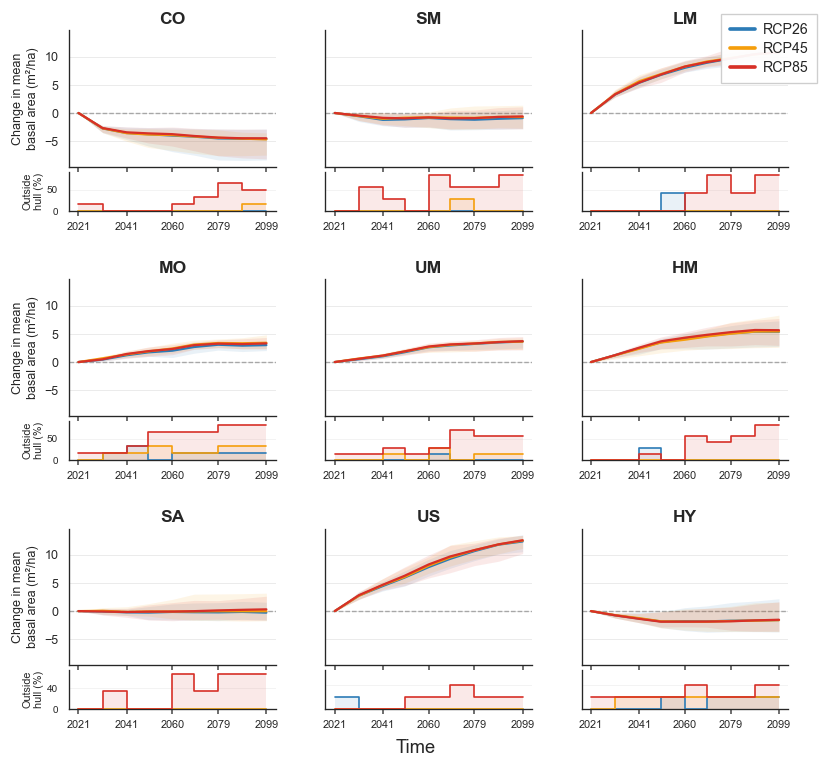

Saved PDF to: ../figures/predictions/hw_proportion_change_by_veg_belt_all_plots.pdf


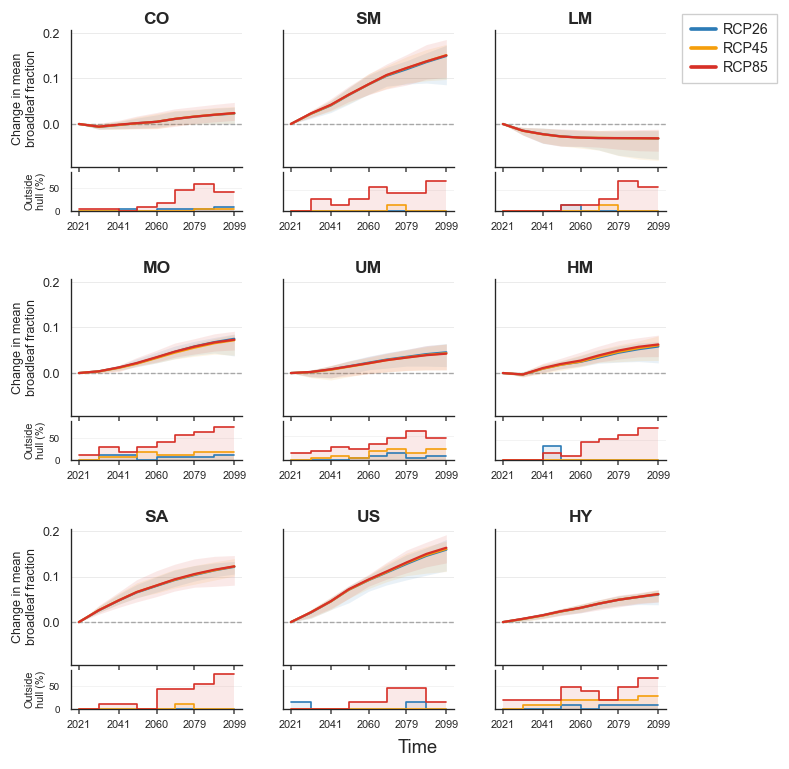

Saved PDF to: ../figures/predictions/hw_proportion_change_by_veg_belt_managed_only.pdf


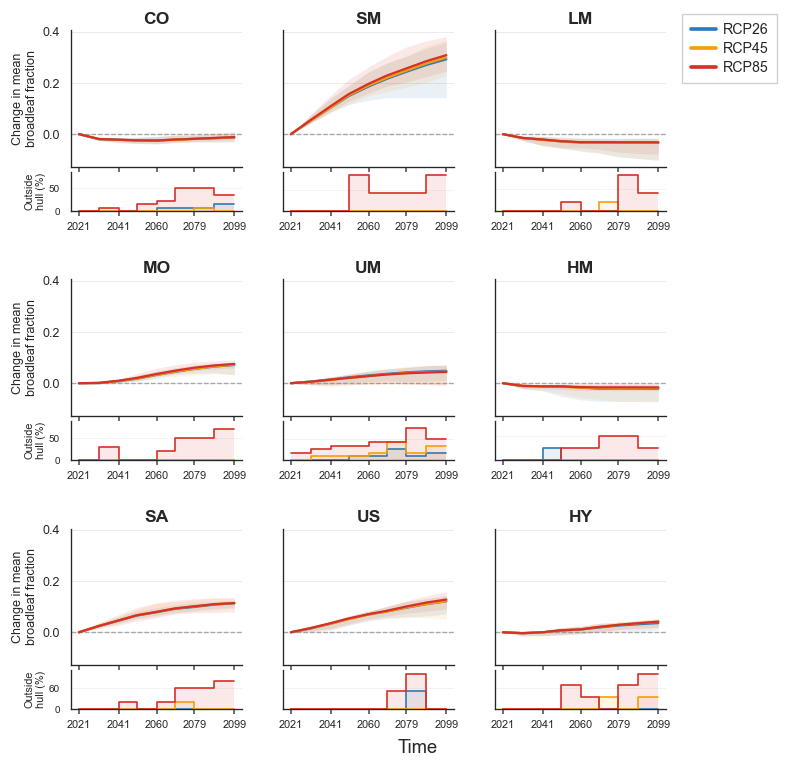

Saved PDF to: ../figures/predictions/hw_proportion_change_by_veg_belt_unmanaged_only.pdf


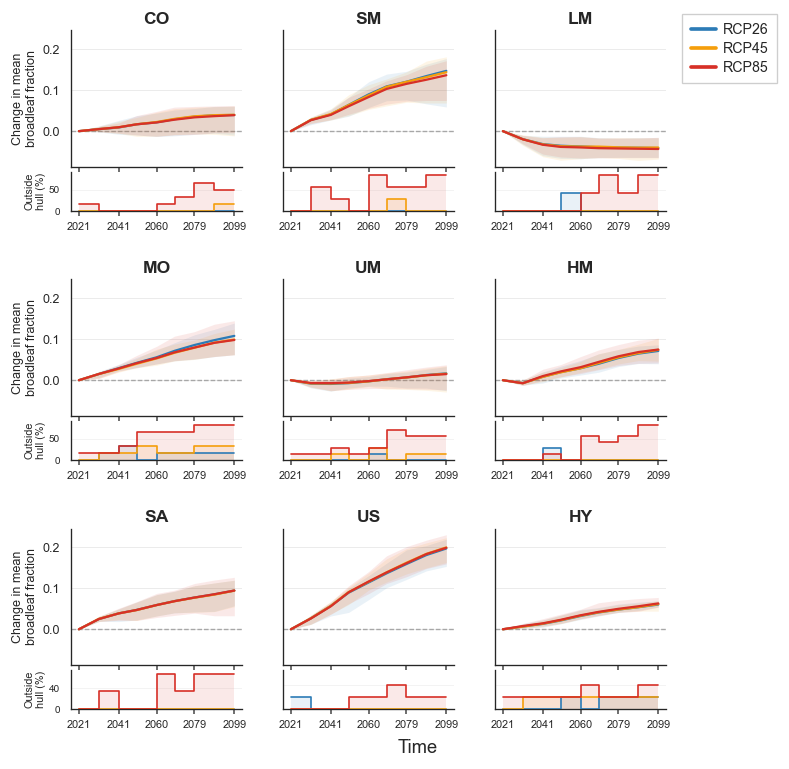

In [7]:
# --- Functions to prepare change-from-baseline data and create plots by vegetation belt ---

def _prepare_veg_belt_data_diff(
    df,
    year_map,
    management_type="All",
    value_col="BASFPH",
    prediction_start_invnr=PREDICTION_START_INVNR,
):
    if management_type == "Managed":
        work_df = df[df["BEWIRTINT1"] == 1.0].copy()
    elif management_type == "Unmanaged":
        work_df = df[df["BEWIRTINT1"] == 3.0].copy()
    else:
        work_df = df.copy()

    fut = work_df[work_df["INVNR"] >= prediction_start_invnr].copy()

    veg_code_map = {k: v["short"] for k, v in VEG_BELT_MAP.items()}
    fut["Vegetation_Belt_Code"] = fut["NAISHSTKOMB"].map(veg_code_map)

    baseline_keys = (
        fut.loc[fut["INVNR"] == prediction_start_invnr, ["rcp", "CLNR", "seed"]]
        .drop_duplicates()
    )
    fut = fut.merge(baseline_keys, on=["rcp", "CLNR", "seed"], how="inner")

    hull_by_belt = calculate_hull_fraction(
        fut.dropna(subset=["Vegetation_Belt_Code"]),
        ["rcp", "INVNR", "Vegetation_Belt_Code"],
        year_map=year_map,
        prediction_start_invnr=prediction_start_invnr,
    )

    baseline = (
        fut.loc[fut["INVNR"] == prediction_start_invnr, ["rcp", "CLNR", "seed", value_col]]
        .rename(columns={value_col: f"{value_col}_start"})
    )
    fut = fut.merge(baseline, on=["rcp", "CLNR", "seed"], how="left")
    fut[f"{value_col}_diff_from_start"] = fut[value_col] - fut[f"{value_col}_start"]

    per_seed = (
        fut.groupby(["rcp", "INVNR", "seed", "Vegetation_Belt_Code"], as_index=False)
           .agg(mean_diff_per_seed=(f"{value_col}_diff_from_start", "mean"))
    )

    agg = (
        per_seed.groupby(["rcp", "INVNR", "Vegetation_Belt_Code"], as_index=False)
                .agg(
                    final_mean_diff=("mean_diff_per_seed", "mean"),
                    min_diff=("mean_diff_per_seed", "min"),
                    max_diff=("mean_diff_per_seed", "max"),
                )
    )

    agg = agg.merge(
        hull_by_belt[["rcp", "INVNR", "Vegetation_Belt_Code", "n_hull_plots", HULL_FRACTION_COL]],
        on=["rcp", "INVNR", "Vegetation_Belt_Code"],
        how="left",
    )
    agg = agg.merge(year_map[["INVNR", "median_year_per_INVNR", "interval_end_year"]], on="INVNR", how="left")
    agg = agg.rename(columns={"median_year_per_INVNR": "mean_year"})
    agg = agg.sort_values(["rcp", "Vegetation_Belt_Code", "mean_year"]).reset_index(drop=True)
    return agg


def _plot_veg_belt_change_facets(
    plot_data,
    title,
    y_label,
    output_filename_base,
    ylim=None,
    legend_outside=False,
):
    """
    Faceted plot: change from baseline per vegetation belt (prediction period only).
    Below each facet: outside-hull % as a small line chart (one line per RCP, same colors).
    legend_outside=True places the RCP legend to the right of the plot area.
    """
    n_cols = 3
    n_rows = 3
    show_hull = HULL_FRACTION_COL in plot_data.columns and plot_data[HULL_FRACTION_COL].notna().any()

    # Compute shared tick positions from actual data years (same for every facet).
    all_years = sorted(plot_data["mean_year"].dropna().unique())
    if len(all_years) >= 3:
        n_show = min(5, len(all_years))
        idxs = np.round(np.linspace(0, len(all_years) - 1, n_show)).astype(int)
        shown_years = [all_years[i] for i in idxs]
    else:
        shown_years = all_years

    fig = plt.figure(figsize=(7.4, 6.5))

    gs_right = 0.80 if legend_outside else 0.94
    outer = fig.add_gridspec(
        n_rows, n_cols,
        left=0.13, right=gs_right, bottom=0.07, top=0.94,
        wspace=0.24, hspace=0.38,
    )

    first_main_ax = None

    for i, veg_code in enumerate(VEG_BELT_ORDER):
        row, col = divmod(i, n_cols)

        if show_hull:
            inner = outer[row, col].subgridspec(2, 1, height_ratios=[3.5, 1.0], hspace=0.06)
            ax = fig.add_subplot(inner[0], sharey=first_main_ax)
            ax_hull = fig.add_subplot(inner[1], sharex=ax)
        else:
            ax = fig.add_subplot(outer[row, col], sharey=first_main_ax)
            ax_hull = None

        if first_main_ax is None:
            first_main_ax = ax

        sub_belt = plot_data[plot_data["Vegetation_Belt_Code"] == veg_code]

        for rcp in rcp_scenarios:
            sub = sub_belt[sub_belt["rcp"] == rcp].sort_values("mean_year")
            if sub.empty:
                continue
            c = COLOR_PALETTE.get(rcp)
            ax.plot(sub["mean_year"], sub["final_mean_diff"], color=c, linewidth=1.35)
            ax.fill_between(sub["mean_year"], sub["min_diff"], sub["max_diff"],
                            color=c, alpha=0.10, linewidth=0)

        ax.set_title(veg_code, fontsize=10.5, weight="bold", pad=4)
        ax.axhline(0, ls="--", color="#7A7A7A", zorder=0, linewidth=0.75)
        if ylim is not None:
            ax.set_ylim(ylim)
        ax.grid(True, axis='y', linewidth=0.45, alpha=0.65)
        ax.grid(False, axis='x')
        ax.set_xticks(shown_years)
        ax.tick_params(axis='both', which='major', labelsize=7.5, color='#555555',
                       length=3, bottom=True)
        ax.tick_params(axis='x', labelbottom=False)
        if col != 0:
            ax.tick_params(axis='y', labelleft=False)
        else:
            ax.set_ylabel(y_label, fontsize=7.5, labelpad=3)
        sns.despine(ax=ax)

        if show_hull:
            for rcp in rcp_scenarios:
                sub = sub_belt[sub_belt["rcp"] == rcp].sort_values("mean_year")
                if sub.empty:
                    continue
                _plot_hull_interval_step(
                    ax_hull, sub, "mean_year", COLOR_PALETTE[rcp],
                    linewidth=1.0, alpha=0.10, zorder=5,
                )

            vmax = sub_belt[HULL_FRACTION_COL].max() * 100 if not sub_belt.empty else 0
            ax_hull.set_ylim(0, max(35, vmax * 1.1))
            ax_hull.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=2, integer=True))
            ax_hull.grid(True, axis='y', linewidth=0.35, alpha=0.5)
            ax_hull.grid(False, axis='x')
            ax_hull.set_xticks(shown_years)
            ax_hull.set_xticklabels([str(int(y)) for y in shown_years])
            ax_hull.tick_params(axis='both', which='major', labelsize=6.0, color='#555555',
                                length=3, bottom=True)
            ax_hull.tick_params(axis='x', labelbottom=True, labelsize=6.5)
            if col != 0:
                ax_hull.tick_params(axis='y', labelleft=False)
            else:
                ax_hull.set_ylabel('Outside\nhull (%)', fontsize=6.5, labelpad=2)
            sns.despine(ax=ax_hull)

    fig.text(0.52, 0.020, "Time", ha="center", va="center", fontsize=AXIS_LABEL_FONTSIZE)

    legend_handles = [Line2D([0], [0], color=COLOR_PALETTE[k], lw=2.2) for k in rcp_scenarios]
    if legend_outside:
        fig.legend(
            handles=legend_handles, labels=rcp_scenarios,
            bbox_to_anchor=(gs_right + 0.01, 0.97), loc='upper left',
            frameon=True, framealpha=0.95, edgecolor='#CCCCCC', fancybox=False,
            fontsize=8.5, handlelength=1.8, handletextpad=0.5,
            borderpad=0.6, labelspacing=0.35,
        )
    else:
        fig.legend(
            handles=legend_handles, labels=rcp_scenarios,
            bbox_to_anchor=(0.98, 0.97), loc='upper right',
            frameon=True, framealpha=0.95, edgecolor='#CCCCCC', fancybox=False,
            fontsize=8.5, handlelength=1.8, handletextpad=0.5,
            borderpad=0.6, labelspacing=0.35,
        )

    if title:
        fig.suptitle(title, fontsize=TITLE_FONTSIZE, weight="bold", y=0.985)

    pdf_path = output_filename_base.with_suffix(".pdf")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved PDF to: {pdf_path}")
    plt.show()


# --- BASFPH change (All / Managed / Unmanaged) ---
data_all_bas = _prepare_veg_belt_data_diff(master_df, year_map, "All", "BASFPH", PREDICTION_START_INVNR)
_plot_veg_belt_change_facets(
    data_all_bas,
    title="",
    y_label="Change in mean\nbasal area (m²/ha)",
    output_filename_base=output_dir / "basal_area_change_by_veg_belt_all_plots"
)

data_man_bas = _prepare_veg_belt_data_diff(master_df, year_map, "Managed", "BASFPH", PREDICTION_START_INVNR)
_plot_veg_belt_change_facets(
    data_man_bas,
    title="",
    y_label="Change in mean\nbasal area (m²/ha)",
    output_filename_base=output_dir / "basal_area_change_by_veg_belt_managed_only"
)

data_unman_bas = _prepare_veg_belt_data_diff(master_df, year_map, "Unmanaged", "BASFPH", PREDICTION_START_INVNR)
_plot_veg_belt_change_facets(
    data_unman_bas,
    title="",
    y_label="Change in mean\nbasal area (m²/ha)",
    output_filename_base=output_dir / "basal_area_change_by_veg_belt_unmanaged_only"
)

# --- HWSW_prop change (All / Managed / Unmanaged) ---
data_all_prop = _prepare_veg_belt_data_diff(master_df, year_map, "All", "HWSW_prop", PREDICTION_START_INVNR)
_plot_veg_belt_change_facets(
    data_all_prop,
    title="",
    y_label="Change in mean\nbroadleaf fraction",
    output_filename_base=output_dir / "hw_proportion_change_by_veg_belt_all_plots",
    legend_outside=True,
)

data_man_prop = _prepare_veg_belt_data_diff(master_df, year_map, "Managed", "HWSW_prop", PREDICTION_START_INVNR)
_plot_veg_belt_change_facets(
    data_man_prop,
    title="",
    y_label="Change in mean\nbroadleaf fraction",
    output_filename_base=output_dir / "hw_proportion_change_by_veg_belt_managed_only",
    legend_outside=True,
)

data_unman_prop = _prepare_veg_belt_data_diff(master_df, year_map, "Unmanaged", "HWSW_prop", PREDICTION_START_INVNR)
_plot_veg_belt_change_facets(
    data_unman_prop,
    title="",
    y_label="Change in mean\nbroadleaf fraction",
    output_filename_base=output_dir / "hw_proportion_change_by_veg_belt_unmanaged_only",
    legend_outside=True,
)